In [48]:
# Units are tracked (sorted on the concatenated recording), so the same unit_id
# is the same neuron in every condition. One figure per unit, conditions as columns:
# baseline -> aligned to movement peaks (contra/ipsi); stim -> aligned to stim onset.
# All rates go through the pipeline's edge-aware Gaussian path so they're comparable.

# Imports + config
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

import RCP_analysis as rcp
from RCP_analysis.python.functions.config_loading import *  # PARAMS, OUT_BASE, roots

%matplotlib inline

FS_INTAN = 30000.0
FS_VEL = 1000.0

WIN_PRE_S = 0.4
WIN_POST_S = 0.4
WIN_MS = (-WIN_PRE_S * 1000.0, WIN_POST_S * 1000.0)

NPRW_RATES = PARAMS.NPRW_rate_est
BIN_MS = float(NPRW_RATES.get("bin_ms", 20.0))
STEP_MS = float(NPRW_RATES.get("step_ms", BIN_MS))
SIGMA_MS = float(NPRW_RATES.get("sigma_ms", 20.0))
NORMALIZE_FIRST_MS = 150.0

# stim-blank params: only applied to stim columns; baseline uses 0/0 (no gap)
STIM_MS_BEFORE = float(NPRW_RATES.get("remove_ms_before", 20.0))
STIM_TAIL_MS = float(NPRW_RATES.get("remove_tail_ms_after", 20.0))

DATA_ROOT = Path(str(PARAMS.data_root))
SESSION_DIR = DATA_ROOT / "Bert/BL_RW_003_Session_1"
SORT_RESULTS = SESSION_DIR / "results" / "checkpoints" / "sorting_results"
CAL_ROOT = SESSION_DIR / "Calibrated"

OUT_FIG_DIR = OUT_BASE / "figures" / "per_unit_cross_condition"
OUT_FIG_DIR.mkdir(parents=True, exist_ok=True)


In [72]:
# One entry per column. `kind` is "baseline" (movement peaks, contra/ipsi) or
# "stim" (stim onset). Paths come from the metadata CSV: Intan_File -> IntanFile_N,
# column-L timestamp -> sorting_results folder. Processing up to Intan #5 / BR #8.
# BR 5 / Intan 2 skipped (metadata: "Bad trial", Has_Stim=0).

# Conditions
CONDITIONS = [
    {
        "label": "Baseline HoB",
        "kind": "baseline",
        "cal": CAL_ROOT / "IntanFile_1" / "BL_closed_loop_STIM_003_004_Cal.mat",
        "spikes": SORT_RESULTS / "BL_closed_loop_STIM_003_250528_140952" / "NPRW" / "spike_trains.mat",
    },
    {
        "label": "Stim (BR6)",
        "kind": "stim",
        "cal": CAL_ROOT / "IntanFile_3" / "BL_closed_loop_STIM_003_006_Cal_stim.mat",
        "spikes": SORT_RESULTS / "BL_closed_loop_STIM_003_250528_143802" / "NPRW" / "spike_trains.mat",
    },
    {
        "label": "Stim (BR7)",
        "kind": "stim",
        "cal": CAL_ROOT / "IntanFile_4" / "BL_closed_loop_STIM_003_007_Cal_stim.mat",
        "spikes": SORT_RESULTS / "BL_closed_loop_STIM_003_250528_144603" / "NPRW" / "spike_trains.mat",
    },
    {
        "label": "Stim (BR8)",
        "kind": "stim",
        "cal": CAL_ROOT / "IntanFile_5" / "BL_closed_loop_STIM_003_008_Cal_stim.mat",
        "spikes": SORT_RESULTS / "BL_closed_loop_STIM_003_250528_145904" / "NPRW" / "spike_trains.mat",
    },
]

In [73]:
# Helper functions
def load_spike_trains(path: Path) -> dict[int, np.ndarray]:
    """spike_trains .mat or .npz -> {unit_id: sample_indices}."""
    trains = {}
    if path.suffix == ".npz":
        data = np.load(path, allow_pickle=True)
        items = ((k, data[k]) for k in data.files)
    else:
        data = loadmat(path, squeeze_me=True)
        items = ((k, v) for k, v in data.items())
    for k, v in items:
        if str(k).startswith("unit_"):  # skip fs and any non-unit fields
            uid = int(str(k).split("unit_")[1])
            trains[uid] = np.asarray(v, dtype=np.int64).ravel()
    return trains


def spike_times_s(unit_train: np.ndarray, intan_start: int) -> np.ndarray:
    """Spike samples -> seconds relative to condition start."""
    spk = np.asarray(unit_train, float)
    spk = spk[spk >= intan_start]  # drop spikes before this condition's recording start
    return (spk - intan_start) / FS_INTAN


def get_gaussian_rates(spk_s, ev_s, ms_before, tail_ms):
    """One unit's spikes + events -> (rates_hz [n_trials, n_bins], rel_t_s)."""
    if ev_s.size == 0:
        return np.zeros((0, 0)), np.zeros(0)
    peaks_ms = {0: spk_s * 1000.0}  # single-key dict: unit flows through rcp as one "channel"
    # bin -> edge-aware Gaussian smooth -> per-trial baseline subtract (same as peri-stim pipeline)
    counts, rel_ms, widths, left_bins = rcp.bin_counts_around_stim(
        peaks_ms, BIN_MS, ev_s * 1000.0, ms_before, tail_ms, WIN_MS, step_ms=STEP_MS,
    )
    rates = rcp.smooth_counts_gauss(counts, widths, rel_ms, SIGMA_MS, left_bins)
    rates = rcp.baseline_zero_each_trial(rates, rel_ms, normalize_first_ms=NORMALIZE_FIRST_MS)
    return rates[:, 0, :], rel_ms / 1000.0  # drop the singleton channel axis


def plot_alignment(ax_raster, ax_psth, spk_s, ev_s, ms_before, tail_ms, color, title):
    """Raster + median PSTH for one alignment (one direction, one condition)."""
    rates, rel_s = get_gaussian_rates(spk_s, ev_s, ms_before, tail_ms)
    for tr, t0 in enumerate(ev_s):  # one raster row per event, spikes relative to event time
        in_win = (spk_s >= t0 - WIN_PRE_S) & (spk_s <= t0 + WIN_POST_S)
        rel = spk_s[in_win] - t0
        ax_raster.plot(rel, np.full(rel.size, tr + 1), ".",
                       color=[0.3, 0.3, 0.3], markersize=3)
    ax_raster.axvline(0, color="r", ls="--", lw=1.2)  # event onset
    ax_raster.set_xlim(-WIN_PRE_S, WIN_POST_S)
    ax_raster.set_ylim(0, max(1, ev_s.size) + 1)
    ax_raster.set_ylabel("Trial")
    ax_raster.set_title(title, fontsize=9)
    if rates.size:
        ax_psth.plot(rel_s, np.nanmedian(rates, axis=0), color=color, lw=1.3)  # median across trials
    ax_psth.axvline(0, color="r", ls="--", lw=1.2)
    ax_psth.set_xlim(-WIN_PRE_S, WIN_POST_S)
    ax_psth.set_ylabel("FR (sp/s)")
    ax_psth.set_xlabel("Time from event (s)")

In [74]:
# Load spike trains for every condition (run once)
# Same unit_id = same neuron across conditions (concatenated sort), so units share an ID space.
per_cond_trains = {c["label"]: load_spike_trains(c["spikes"]) for c in CONDITIONS}
available_units = sorted(per_cond_trains[CONDITIONS[0]["label"]].keys())
print(f"{len(available_units)} units across {len(CONDITIONS)} conditions")
print("units:", available_units)

140 units across 4 conditions
units: [6, 7, 8, 10, 11, 24, 28, 31, 37, 39, 40, 41, 43, 44, 46, 47, 48, 50, 52, 53, 54, 56, 58, 59, 60, 61, 62, 65, 66, 67, 68, 69, 71, 72, 73, 75, 77, 78, 79, 80, 81, 82, 83, 84, 86, 88, 89, 92, 94, 95, 96, 97, 98, 100, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 134, 135, 136, 137, 139, 141, 143, 146, 147, 149, 150, 151, 152, 154, 155, 156, 158, 159, 162, 163, 164, 165, 166, 168, 169, 170, 171, 172, 173, 174, 175, 176, 178, 179, 180, 181, 182, 184, 185, 186, 187, 188, 190, 191, 192, 193, 194, 197, 198, 199, 200, 201, 203, 206, 210, 215, 218, 226]


In [75]:
# Pre-load Cal data per condition (run once)
# Cal files are MATLAB v7.3 (HDF5). Read only the fields we need via h5py so we
# don't pull the whole large file into RAM. Note: h5py returns MATLAB arrays
# transposed, so a MATLAB (n,2) matrix is (2,n) here and (:,1) -> raw[0,:].
import h5py

def load_cal_fields(cal_path):
    """Read Intan_idx, headYawVel, and contra/ipsi peak times from a v7.3 Cal file."""
    with h5py.File(str(cal_path), "r") as f:
        data = f["Data"]
        intan_start = int(np.asarray(data["Intan_idx"]).ravel()[0])  # condition's first sample index
        vel = np.asarray(data["headYawVel"], float).ravel()
        seg = data["segments"]
        pos = np.asarray(seg["active_like_stim_pos"], float)
        neg = np.asarray(seg["active_like_stim_neg"], float)
        # row 0 = MATLAB column 1 = peak times (ms); guard the single-peak (1-D) case
        pos_times = pos[0, :] if pos.ndim == 2 else pos.ravel()
        neg_times = neg[0, :] if neg.ndim == 2 else neg.ravel()
    return intan_start, vel, pos_times, neg_times


cond_cache = {}  # per-condition data that doesn't change per unit; computed once
for cond in CONDITIONS:
    intan_start, vel, pos_times, neg_times = load_cal_fields(cond["cal"])
    t_vel = np.arange(vel.size) / FS_VEL
    # contra from neg, ipsi from pos (matches MATLAB); ms -> s. Same mapping for baseline and stim.
    events = {"contra": neg_times / 1000.0, "ipsi": pos_times / 1000.0}
    cond_cache[cond["label"]] = dict(
        intan_start=intan_start, vel=vel, t_vel=t_vel,
        kind=cond["kind"], events=events,
    )
    n_ev = sum(len(v) for v in events.values())
    print(f"{cond['label']}: intan_start={intan_start}, {n_ev} events, vel {vel.size} samples")

Baseline HoB: intan_start=6015514, 12 events, vel 67270 samples
Stim (BR6): intan_start=58116, 64 events, vel 222012 samples
Stim (BR7): intan_start=92175, 77 events, vel 258503 samples
Stim (BR8): intan_start=199125, 89 events, vel 379836 samples


In [65]:
cond['cal']

PosixPath('/home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/Calibrated/IntanFile_5/BL_closed_loop_STIM_003_008_Cal_stim.mat')

trial cap: contra n=7, ipsi n=5


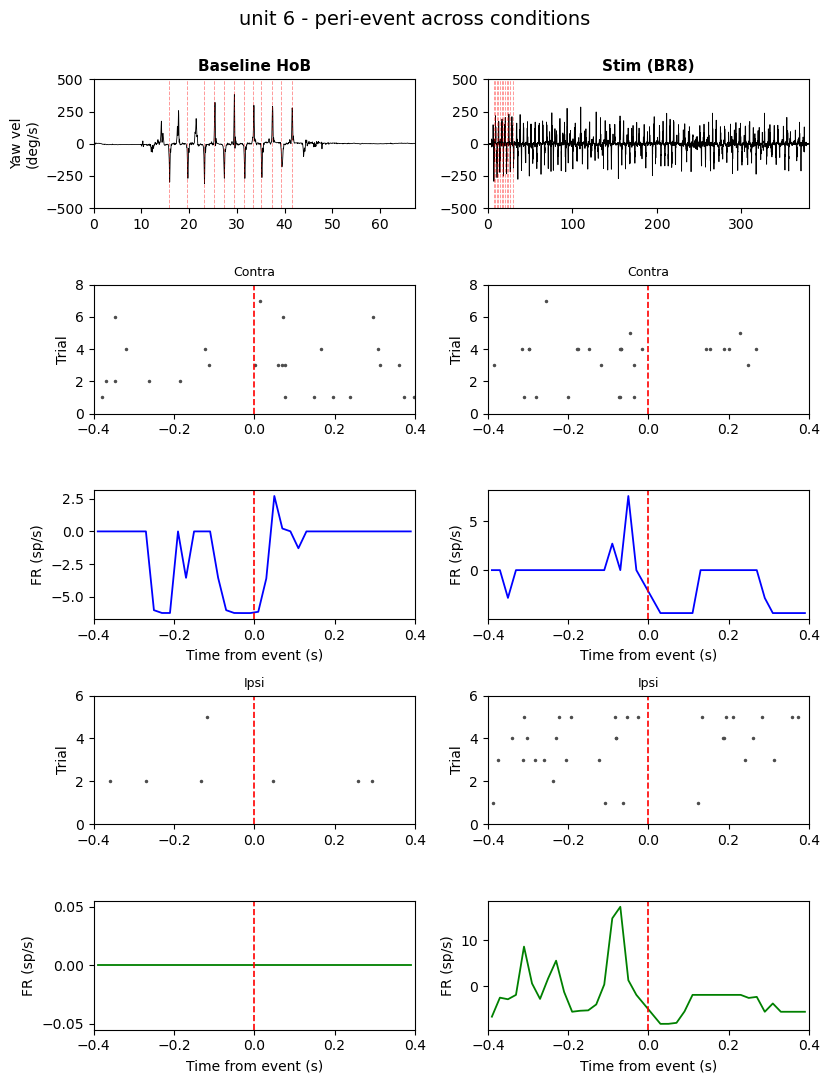

In [76]:
# Plot ONE unit inline: Baseline HoB vs Stim (BR8), contra + ipsi
# Change `uid` and re-run to inspect different units.
uid = 6

# Subset the columns to plot without touching the master CONDITIONS list
plot_conds = [c for c in CONDITIONS if c["label"] in ("Baseline HoB", "Stim (BR8)")]

# Cap each direction to the smallest n across plotted columns, so trial counts match.
# [:n] keeps the EARLIEST n events (arrays are time-ordered) and also caps the PSTH,
# not just the raster — raster and PSTH stay on the same trials.
n_contra = min(cond_cache[c["label"]]["events"]["contra"].size for c in plot_conds)
n_ipsi   = min(cond_cache[c["label"]]["events"]["ipsi"].size   for c in plot_conds)
print(f"trial cap: contra n={n_contra}, ipsi n={n_ipsi}")

n_cols = len(plot_conds)
n_rows = 5  # row 0: velocity | 1-2: contra raster/psth | 3-4: ipsi raster/psth
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 11), squeeze=False)

for c, cond in enumerate(plot_conds):
    label = cond["label"]
    cc = cond_cache[label]
    # same unit_id across conditions; empty train if this unit is absent in this file
    spk_s = spike_times_s(per_cond_trains[label].get(uid, np.zeros(0, np.int64)), cc["intan_start"])

    # Row 0: head yaw velocity with event markers
    ax_vel = axes[0][c]
    ax_vel.plot(cc["t_vel"], cc["vel"], color="k", lw=0.6)
    ax_vel.set_ylim(-500, 500)
    ax_vel.set_xlim(0, cc["t_vel"][-1] if cc["t_vel"].size else 1)
    ax_vel.set_title(label, fontsize=11, fontweight="bold")
    if c == 0:
        ax_vel.set_ylabel("Yaw vel\n(deg/s)")

    contra = cc["events"]["contra"][:n_contra]  # capped to matched n
    ipsi   = cc["events"]["ipsi"][:n_ipsi]
    for p in np.concatenate([contra, ipsi]):
        ax_vel.axvline(p, color="r", ls="--", alpha=0.4, lw=0.7)

    # baseline: align to movement peaks, no blank gap.
    # stim: blank ±stim window around each onset so the artifact doesn't leak into the rate.
    if cc["kind"] == "baseline":
        msb, tail = 0.0, 0.0
    else:
        msb, tail = STIM_MS_BEFORE, STIM_TAIL_MS

    # Rows read down across columns: contra PSTH (row 2) baseline vs stim, etc.
    plot_alignment(axes[1][c], axes[2][c], spk_s, contra, msb, tail, "b", "Contra")
    plot_alignment(axes[3][c], axes[4][c], spk_s, ipsi, msb, tail, "g", "Ipsi")

fig.suptitle(f"unit {uid} - peri-event across conditions", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

In [ ]:
# Batch-save all units to PNG
# Only run when you want the full set on disk. Closes each figure so the kernel
# doesn't hold hundreds open. This repeats the plotting cell above inside a loop —
# once you're happy with the single-unit layout, you can factor it into a function.

# %%
SAVE_ALL = False  # flip to True to run

if SAVE_ALL:
    for uid in available_units:
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 11), squeeze=False)
        for c, cond in enumerate(CONDITIONS):
            label = cond["label"]
            cc = cond_cache[label]
            spk_s = spike_times_s(per_cond_trains[label].get(uid, np.zeros(0, np.int64)), cc["intan_start"])
            ax_vel = axes[0][c]
            ax_vel.plot(cc["t_vel"], cc["vel"], color="k", lw=0.6)
            ax_vel.set_ylim(-500, 500)
            ax_vel.set_xlim(0, cc["t_vel"][-1] if cc["t_vel"].size else 1)
            ax_vel.set_title(label, fontsize=11, fontweight="bold")
            if c == 0:
                ax_vel.set_ylabel("Yaw vel\n(deg/s)")
            if cc["kind"] == "baseline":
                contra, ipsi = cc["events"]["contra"], cc["events"]["ipsi"]
                for p in np.concatenate([contra, ipsi]):
                    ax_vel.axvline(p, color="r", ls="--", alpha=0.4, lw=0.7)
                plot_alignment(axes[1][c], axes[2][c], spk_s, contra, 0.0, 0.0, "b", "Contra raster")
                plot_alignment(axes[3][c], axes[4][c], spk_s, ipsi, 0.0, 0.0, "g", "Ipsi raster")
            else:
                stim = cc["events"]["stim"]
                for p in stim:
                    ax_vel.axvline(p, color="m", ls="--", alpha=0.3, lw=0.6)
                plot_alignment(axes[1][c], axes[2][c], spk_s, stim, STIM_MS_BEFORE, STIM_TAIL_MS, "m", "Stim raster")
                axes[3][c].axis("off")
                axes[4][c].axis("off")
        fig.suptitle(f"unit {uid} - peri-event across conditions", fontsize=14)
        fig.tight_layout(rect=[0, 0, 1, 0.98])
        fig.savefig(OUT_FIG_DIR / f"unit_{uid:03d}_cross_condition.png", dpi=150, bbox_inches="tight")
        plt.close(fig)
        print(f"saved unit {uid}")